# Домашнее задание 1

Утва Дмитрий Алексеевич

Рекомендую 10 ещё не оценённых музыкальных товаров. Релевантность: будущая оценка 4 или 5. Настройки выбираю по NDCG@10.

Запуск (Python 3.12):

```bash
python3.12 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
python run_notebook.py
```

Данные скачиваются в `.data/` (236 МБ), ссылки и SHA-256 находятся в `data_manifest.json`. Seed = 42, CPU, один поток.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", ".cache/matplotlib")

import json
import random
import platform
import sys
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

from data import download_data, prepare_data, TRAIN_END, VALID_END
from models import ItemKNN, ImplicitALS, EASE, FactorizationMachine, CustomTargetALS
from models.base import interaction_matrix
from experiment import SEED, SEARCH, tune, final_comparison, metadata_ablation
from evaluation import paired_bootstrap

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
blas_limit = threadpool_limits(limits=1)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
Path("results").mkdir(exist_ok=True)
environment = {"python": platform.python_version(), "platform": platform.platform(),
               "seed": SEED, "torch_threads": torch.get_num_threads(),
               "packages": {name: version(name) for name in
                            ["numpy", "scipy", "pandas", "torch", "matplotlib", "nbformat", "nbclient"]}}
print(json.dumps(environment, indent=2))

{
  "python": "3.12.14",
  "platform": "macOS-26.7-arm64-arm-64bit",
  "seed": 42,
  "torch_threads": 1,
  "packages": {
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.0",
    "torch": "2.14.1",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0"
  }
}


## Данные

[Amazon Reviews 2018, Musical Instruments](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html). Полный CSV оценок и JSON метаданных. [Статья о датасете](https://aclanthology.org/D19-1018/).

Поля CSV: `item` (товар), `user` (пользователь), `rating` (1-5), `timestamp` (дата отзыва в Unix seconds). В метаданных есть название, бренд и категория товара. Объёмы до и после обработки:

In [2]:
data_dir = download_data()
dataset = prepare_data(data_dir)
stats = dataset["stats"]
volume = pd.DataFrame([
    {"stage": "Исходный CSV", "interactions": stats["raw_rows"], "users": stats["raw_users"], "items": stats["raw_items"]},
    {"stage": "После очистки", "interactions": stats["clean_rows"], "users": np.nan, "items": np.nan},
    {"stage": "Используемая выборка", "interactions": stats["sample_rows"], "users": stats["users"], "items": stats["items"]},
]).set_index("stage")
display(volume)
print(f"Разреженность выборки: {stats['sparsity']:.6%}")
print(f"Доля оценок 4-5: {stats['positive_share']:.2%}")
assert 100_000 <= len(dataset["sample"]) <= 2_000_000
assert min(dataset["shape"]) >= 1_000

,interactions,users,items
stage,,,
Исходный CSV,1512530,903330.0,112222.0
После очистки,1470564,NaN,NaN
Используемая выборка,160207,33285.0,2979.0


Разреженность выборки: 99.838429%
Доля оценок 4-5: 87.16%


## Подготовка

Удаляю пропуски, некорректные оценки и даты. Для повторных user-item оставляю первый отзыв, при одинаковой дате беру меньшую оценку.

По train выбираю 3000 самых популярных товаров (при равенстве по ASIN), затем пользователей с 3+ отзывами в этом каталоге. Удаляю товары, оставшиеся без обучающих событий. ID и состав выборки фиксируются по train. Ограничение товаров нужно для памяти EASE, пользователей отбираю по наличию истории.

In [3]:
display(pd.Series(stats["missing_by_column"], name="Пропуски в CSV").to_frame())
display(pd.Series({key: stats[key] for key in ["exact_duplicate_rows", "duplicate_user_item_rows",
                                             "invalid_or_missing_rows", "metadata_source_rows",
                                             "metadata_repeated_selected_items", "items_without_metadata",
                                             "brands", "categories"]}, name="count").to_frame())
display(pd.Series(stats["unknown_by_field"], name="unknown в выбранном каталоге").to_frame())
print("Повторные строки метаданных: сохраняется первая запись ASIN в исходном файле.")

,Пропуски в CSV
item,0
user,0
rating,0
timestamp,0


,count
exact_duplicate_rows,39241
duplicate_user_item_rows,41966
invalid_or_missing_rows,0
metadata_source_rows,120310
metadata_repeated_selected_items,562
items_without_metadata,2
brands,834
categories,314


,unknown в выбранном каталоге
title,2
brand,22
category,97


Повторные строки метаданных: сохраняется первая запись ASIN в исходном файле.


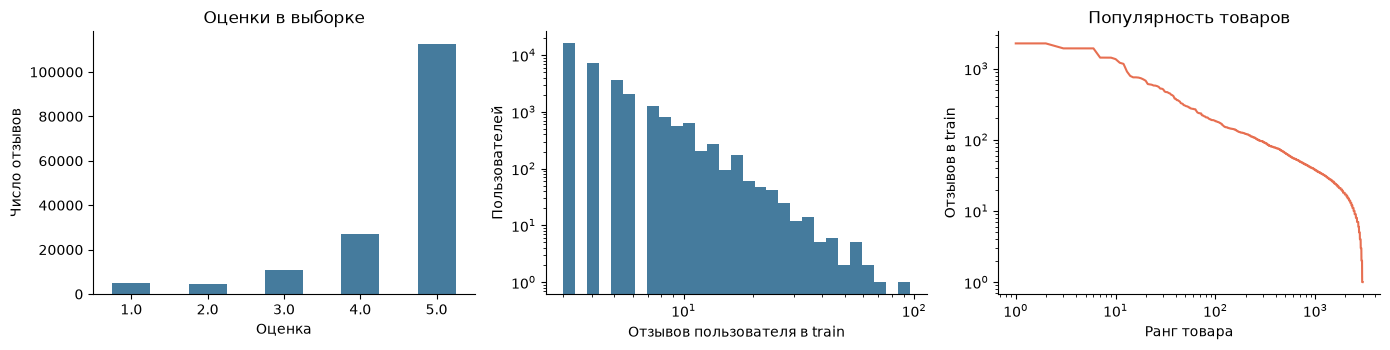

,user_activity,item_popularity
count,33285.000000,2979.000000
mean,4.532853,50.646526
std,2.964393,127.078135
min,3.000000,1.000000
25%,3.000000,14.000000
50%,4.000000,26.000000
75%,5.000000,47.000000
max,95.000000,2261.000000


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
dataset["sample"].rating.value_counts().sort_index().plot.bar(ax=axes[0], color="#457b9d", rot=0)
axes[0].set(xlabel="Оценка", ylabel="Число отзывов", title="Оценки в выборке")
activity = dataset["train"].groupby("u").size()
popularity = dataset["train"].groupby("i").size()
axes[1].hist(activity, bins=np.geomspace(activity.min(), activity.max() + 1, 30), color="#457b9d")
axes[1].set(xscale="log", yscale="log", xlabel="Отзывов пользователя в train", ylabel="Пользователей")
axes[2].plot(np.arange(1, len(popularity) + 1), np.sort(popularity)[::-1], color="#e76f51")
axes[2].set(xscale="log", yscale="log", xlabel="Ранг товара", ylabel="Отзывов в train", title="Популярность товаров")
fig.tight_layout()
fig.savefig("results/eda.png", dpi=140)
plt.show()
display(pd.DataFrame({"user_activity": activity.describe(), "item_popularity": popularity.describe()}))

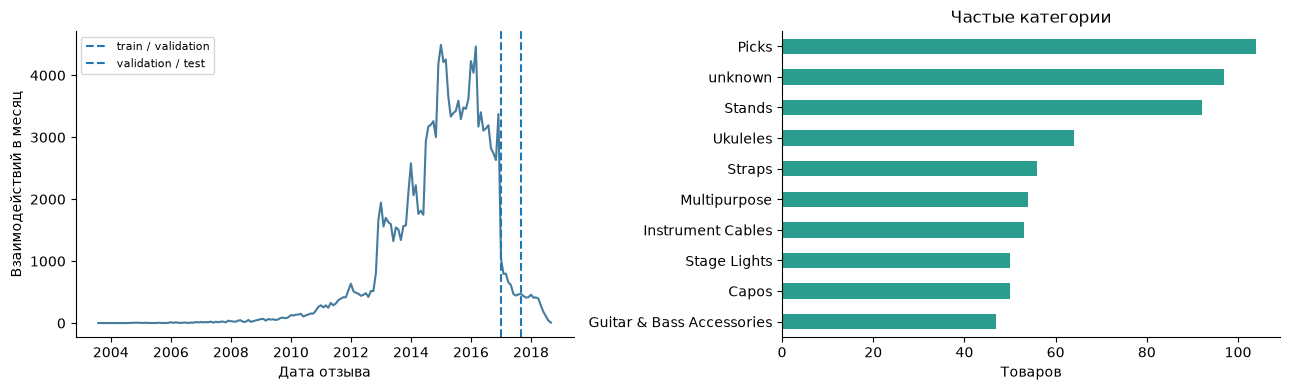

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dates = pd.to_datetime(dataset["sample"].timestamp, unit="s", utc=True)
by_month = dates.dt.strftime("%Y-%m").value_counts().sort_index()
axes[0].plot(pd.to_datetime(by_month.index), by_month.values, color="#457b9d")
for boundary, label in [(TRAIN_END, "train / validation"), (VALID_END, "validation / test")]:
    axes[0].axvline(pd.to_datetime(boundary, unit="s"), linestyle="--", label=label)
axes[0].set(xlabel="Дата отзыва", ylabel="Взаимодействий в месяц")
axes[0].legend(fontsize=8)
dataset["metadata"].category.value_counts().head(10).sort_values().plot.barh(ax=axes[1], color="#2a9d8f")
axes[1].set(xlabel="Товаров", ylabel="", title="Частые категории")
fig.tight_layout()
fig.savefig("results/time_and_categories.png", dpi=140)
plt.show()

87% оценок равны 4-5, активность и популярность распределены неравномерно.

Для FM беру бренд и конечную категорию: они объединяют похожие товары. Пропуски заменяю на `unknown`. Предполагаю, что эти свойства были известны в прошлом; истории изменений метаданных нет. Текст отзывов, цену и `also_buy` не использую.

## Оценка

Общие границы в UTC:

* train: до 01.01.2017;
* validation: с 01.01.2017 до 01.09.2017;
* test: с 01.09.2017 до конца данных.

Подбор идёт на validation. Затем переобучаю на train + validation и один раз сравниваю на test. Каталог фиксирован по train.

У всех моделей одинаковые пользователи и кандидаты: весь каталог без ранее оценённых товаров, включая оценки 1-3. При равном score выбирается меньший ID. Новые пользователи и товары исключены. Считаю метрики для пользователей хотя бы с одним релевантным товаром в периоде.

Основная метрика NDCG@10 учитывает позиции попаданий. Recall@10 показывает долю найденных релевантных товаров. Усреднение по пользователям. Дополнительно: HitRate@10 и доля каталога, попавшая в рекомендации.

In [6]:
split_rows = []
for name, frame in [("train", dataset["train"]), ("validation", dataset["valid"]), ("test", dataset["test"])]:
    split_rows.append({"split": name, "events": len(frame), "users": frame.u.nunique(),
                       "items": frame.i.nunique(), "positive_events": int((frame.rating >= 4).sum()),
                       "first": pd.to_datetime(frame.timestamp.min(), unit="s", utc=True),
                       "last": pd.to_datetime(frame.timestamp.max(), unit="s", utc=True)})
display(pd.DataFrame(split_rows).set_index("split"))
display(dataset["exclusions"])
print("Общий каталог кандидатов:", dataset["shape"][1])
print("Проверка временных границ и отсутствия повторных пар выполнена в prepare_data().")

,events,users,items,positive_events,first,last
split,,,,,,
train,150876,33285,2979,131781,2003-08-26 00:00:00+00:00,2016-12-31 00:00:00+00:00
validation,5287,2959,1578,4535,2017-01-01 00:00:00+00:00,2017-08-31 00:00:00+00:00
test,4044,2361,1322,3328,2017-09-01 00:00:00+00:00,2018-09-10 00:00:00+00:00


,all_clean_events,cold_user_or_item_vs_train,warm_but_outside_sample,selected_events,selected_users,users_with_positive
split,,,,,,
validation,188434,143016,40131,5287,2959,2604
test,205039,166577,34418,4044,2361,2016


Общий каталог кандидатов: 2979
Проверка временных границ и отсутствия повторных пар выполнена в prepare_data().


## Модели

Реализации в `models/`. $X_{ui}=1$ для оценок 4-5, иначе 0.

### ItemKNN

Cosine со сглаживанием по числу общих пользователей:

$$s_{ij}=\frac{X_i^\top X_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+\beta},\quad n_{ij}=X_i^\top X_j.$$

При $\beta=0$ сглаживания нет; при нулевой норме сходство 0. Диагональ обнуляю, оставляю top-k положительных соседей каждого товара. Score: $X_uS$.

### iALS

$p=X$. Confidence $c=1+\alpha$ для всех наблюдений, иначе 1.

$$\min_{A,B}\sum_{u,i}c_{ui}(p_{ui}-a_u^\top b_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$

Поочерёдно обновляю факторы пользователей и товаров, решая системы через Cholesky. Score: $a_u^\top b_i$.

### EASE

$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad \operatorname{diag}(W)=0.$$

$P=(X^\top X+\lambda I)^{-1}$, $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$. Score: $XW$.

### FM

One-hot признаки: user, item, бренд, категория.

$$f(x)=w_0+\sum_jw_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$

Обучение: BCE, Adam с L2. Метка 1 для оценок 4-5, иначе 0. На каждый положительный пример добавляю три равномерных неизвестных товара с меткой 0, с возвращением, заново в каждой эпохе. Будущие события при выборе негативов не используются.

Ниже пространство поиска. При равном NDCG выбираю первый вариант. На test также сравню FM с метаданными и без них при одинаковых настройках.

In [7]:
search_table = pd.DataFrame([{"model": name, "config_id": i, **params}
                             for name, configs in SEARCH.items() for i, params in enumerate(configs)])
display(search_table.astype(object).fillna(""))
print("CustomALS: параметры базового iALS, выбранные на validation; half_life_days ∈ {180, 365, 730}.")
print("При равном NDCG выбирается первый вариант в заранее заданном порядке.")
print("План финальной абляции: FM без brand/category с теми же выбранными параметрами.")
validation_tables = []
chosen = {}

,model,config_id,neighbors,shrinkage,factors,alpha,regularization,iterations,seed,learning_rate,weight_decay,epochs,negatives,batch_size,use_metadata
0,ItemKNN,0,30.0,0.0,,,,,,,,,,,
1,ItemKNN,1,50.0,10.0,,,,,,,,,,,
2,ItemKNN,2,100.0,30.0,,,,,,,,,,,
3,iALS,0,,,32.0,10.0,1.0,12.0,42.0,,,,,,
4,iALS,1,,,32.0,40.0,5.0,12.0,42.0,,,,,,
5,iALS,2,,,64.0,20.0,5.0,12.0,42.0,,,,,,
6,EASE,0,,,,,30.0,,,,,,,,
7,EASE,1,,,,,100.0,,,,,,,,
8,EASE,2,,,,,300.0,,,,,,,,
9,FM,0,,,16.0,,,,42.0,0.01,0.00001,8.0,3.0,2048.0,True


CustomALS: параметры базового iALS, выбранные на validation; half_life_days ∈ {180, 365, 730}.
При равном NDCG выбирается первый вариант в заранее заданном порядке.
План финальной абляции: FM без brand/category с теми же выбранными параметрами.


In [8]:
table, chosen["ItemKNN"] = tune("ItemKNN", SEARCH["ItemKNN"], dataset)
validation_tables.append(table)
display(table[["config_id", "NDCG@10", "Recall@10", "fit_seconds", "params"]])

ItemKNN 1/3: NDCG@10=0.02802, Recall@10=0.04599, fit=0.2s


ItemKNN 2/3: NDCG@10=0.03558, Recall@10=0.05882, fit=0.2s


ItemKNN 3/3: NDCG@10=0.03647, Recall@10=0.06013, fit=0.1s


,config_id,NDCG@10,Recall@10,fit_seconds,params
0,0,0.028015,0.045991,0.170610,"{""neighbors"": 30, ""shrinkage"": 0}"
1,1,0.035575,0.058822,0.172274,"{""neighbors"": 50, ""shrinkage"": 10}"
2,2,0.036469,0.060126,0.133705,"{""neighbors"": 100, ""shrinkage"": 30}"


In [9]:
table, chosen["iALS"] = tune("iALS", SEARCH["iALS"], dataset)
validation_tables.append(table)
display(table[["config_id", "NDCG@10", "Recall@10", "fit_seconds", "params"]])

iALS 1/3: NDCG@10=0.03116, Recall@10=0.05466, fit=5.1s


iALS 2/3: NDCG@10=0.03491, Recall@10=0.06266, fit=5.1s


iALS 3/3: NDCG@10=0.03162, Recall@10=0.05536, fit=10.5s


,config_id,NDCG@10,Recall@10,fit_seconds,params
0,0,0.031160,0.054655,5.099354,"{""alpha"": 10, ""factors"": 32, ""iterations"": 12, ""regularization"": 1, ""seed"": 42}"
1,1,0.034909,0.062655,5.076704,"{""alpha"": 40, ""factors"": 32, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"
2,2,0.031623,0.055363,10.467093,"{""alpha"": 20, ""factors"": 64, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"


In [10]:
table, chosen["EASE"] = tune("EASE", SEARCH["EASE"], dataset)
validation_tables.append(table)
display(table[["config_id", "NDCG@10", "Recall@10", "fit_seconds", "params"]])

EASE 1/3: NDCG@10=0.03457, Recall@10=0.06129, fit=0.3s


EASE 2/3: NDCG@10=0.03685, Recall@10=0.06603, fit=0.2s


EASE 3/3: NDCG@10=0.03513, Recall@10=0.06382, fit=0.2s


,config_id,NDCG@10,Recall@10,fit_seconds,params
0,0,0.034574,0.061285,0.281126,"{""regularization"": 30}"
1,1,0.036846,0.066029,0.231010,"{""regularization"": 100}"
2,2,0.035125,0.063824,0.228907,"{""regularization"": 300}"


In [11]:
table, chosen["FM"] = tune("FM", SEARCH["FM"], dataset)
validation_tables.append(table)
display(table[["config_id", "NDCG@10", "Recall@10", "fit_seconds", "params"]])

FM 1/3: NDCG@10=0.02689, Recall@10=0.04598, fit=2.8s


FM 2/3: NDCG@10=0.02714, Recall@10=0.04345, fit=6.4s


FM 3/3: NDCG@10=0.02065, Recall@10=0.02966, fit=4.2s


,config_id,NDCG@10,Recall@10,fit_seconds,params
0,0,0.026889,0.045976,2.791885,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 16, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""use_metadata"": true, ""weight_decay"": 1e-05}"
1,1,0.027135,0.043446,6.443154,"{""batch_size"": 2048, ""epochs"": 12, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""use_metadata"": true, ""weight_decay"": 1e-05}"
2,2,0.020646,0.029656,4.243306,"{""batch_size"": 2048, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""use_metadata"": true, ""weight_decay"": 0.0001}"


### Собственный таргет ALS

Учитываю силу оценки и давность:

$$q_{ui}=\frac{r_{ui}-3}{2}\left(0.5+0.5\cdot2^{-(T-t_{ui})/(86400h)}\right).$$

$T$ является границей обучения, $h$ задаётся в днях. Неизвестные пары имеют таргет 0. Низкие оценки дают отрицательный сигнал, старые отзывы слабее влияют на результат.

Заменяю $p$ на $q$ в iALS. Confidence и параметры оставляю как у выбранного базового iALS, подбираю только $h\in\{180,365,730\}$. Релевантность на test остаётся `rating >= 4`.

In [12]:
custom_space = [{**chosen["iALS"], "half_life_days": h} for h in [180, 365, 730]]
table, chosen["CustomALS"] = tune("CustomALS", custom_space, dataset)
validation_tables.append(table)
display(table[["config_id", "NDCG@10", "Recall@10", "fit_seconds", "params"]])

validation = pd.concat(validation_tables, ignore_index=True)
validation.to_csv("results/validation.csv", index=False)
Path("results/selected_params.json").write_text(json.dumps(chosen, indent=2), encoding="utf-8")
display(pd.DataFrame([{"model": name, "selected_params": json.dumps(params, sort_keys=True)}
                      for name, params in chosen.items()]).set_index("model"))
print("Все настройки сохранены. Далее начинается финальная оценка на test.")

CustomALS 1/3: NDCG@10=0.02908, Recall@10=0.04952, fit=5.1s


CustomALS 2/3: NDCG@10=0.02959, Recall@10=0.05134, fit=5.0s


CustomALS 3/3: NDCG@10=0.02831, Recall@10=0.04927, fit=5.0s


,config_id,NDCG@10,Recall@10,fit_seconds,params
0,0,0.029078,0.049520,5.073204,"{""alpha"": 40, ""factors"": 32, ""half_life_days"": 180, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"
1,1,0.029593,0.051342,5.022140,"{""alpha"": 40, ""factors"": 32, ""half_life_days"": 365, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"
2,2,0.028310,0.049268,5.037447,"{""alpha"": 40, ""factors"": 32, ""half_life_days"": 730, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"


,selected_params
model,
ItemKNN,"{""neighbors"": 100, ""shrinkage"": 30}"
iALS,"{""alpha"": 40, ""factors"": 32, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"
EASE,"{""regularization"": 100}"
FM,"{""batch_size"": 2048, ""epochs"": 12, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""use_metadata"": true, ""weight_decay"": 1e-05}"
CustomALS,"{""alpha"": 40, ""factors"": 32, ""half_life_days"": 365, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"


Все настройки сохранены. Далее начинается финальная оценка на test.


## Результаты

Все модели переобучены на train + validation. Для custom-таргета $T=01.09.2017$.

In [13]:
test_results, per_user = final_comparison(dataset, chosen)
test_results.to_csv("results/test.csv")
display(test_results.sort_values("NDCG@10", ascending=False))
assert test_results.n_users.nunique() == 1
assert all(per_user[name].index.equals(per_user["iALS"].index) for name in per_user)

Test ItemKNN: NDCG@10=0.02361, Recall@10=0.04251


Test iALS: NDCG@10=0.02446, Recall@10=0.04244


Test EASE: NDCG@10=0.02709, Recall@10=0.05017


Test FM: NDCG@10=0.02550, Recall@10=0.04404


Test CustomALS: NDCG@10=0.02397, Recall@10=0.04354


,NDCG@10,Recall@10,HitRate@10,CatalogCoverage@10,n_users,fit_seconds,evaluation_seconds,params
model,,,,,,,,
EASE,0.027092,0.050174,0.071925,0.455858,2016,0.274553,0.435013,"{""regularization"": 100}"
FM,0.025500,0.044035,0.065972,0.155757,2016,6.683501,0.253470,"{""batch_size"": 2048, ""epochs"": 12, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""use_metadata"": true, ""weight_decay"": 1e-05}"
iALS,0.024461,0.042440,0.063492,0.263847,2016,5.083151,0.323266,"{""alpha"": 40, ""factors"": 32, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"
CustomALS,0.023972,0.043541,0.064980,0.243706,2016,5.161014,0.257073,"{""alpha"": 40, ""factors"": 32, ""half_life_days"": 365, ""iterations"": 12, ""regularization"": 5, ""seed"": 42}"
ItemKNN,0.023609,0.042510,0.058036,0.591138,2016,0.205193,0.145499,"{""neighbors"": 100, ""shrinkage"": 30}"


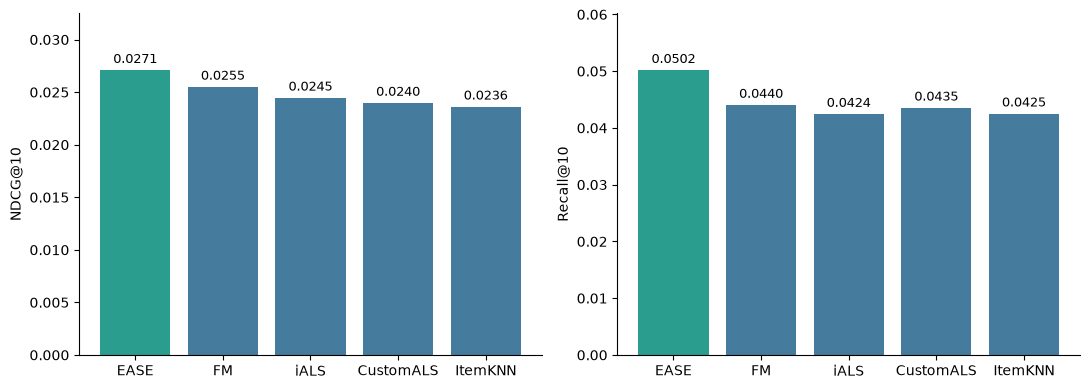

In [14]:
ordered = test_results.sort_values("NDCG@10", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["NDCG@10", "Recall@10"]):
    bars = ax.bar(ordered.index, ordered[metric], color=["#2a9d8f"] + ["#457b9d"] * 4)
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
    ax.set(ylabel=metric, ylim=(0, ordered[metric].max() * 1.2))
fig.tight_layout()
fig.savefig("results/model_comparison.png", dpi=160)
plt.show()

Проверка метаданных: FM только с ID при тех же настройках. Для разницы NDCG считаю парный bootstrap по пользователям: 2000 повторов, интервал 95%.

In [15]:
ablation_scores, ablation_users = metadata_ablation(dataset, chosen["FM"])
ablation = pd.DataFrame([test_results.loc["FM", list(ablation_scores)].to_dict(), ablation_scores],
                        index=["FM с метаданными", "FM только ID"])
ablation.to_csv("results/fm_ablation.csv")
display(ablation)
comparisons = pd.DataFrame({
    "CustomALS − iALS": paired_bootstrap(per_user["CustomALS"], per_user["iALS"]),
    "FM с метаданными − FM только ID": paired_bootstrap(per_user["FM"], ablation_users),
}).T
comparisons.to_csv("results/paired_comparisons.csv")
display(comparisons)

,NDCG@10,Recall@10,HitRate@10,CatalogCoverage@10,n_users
FM с метаданными,0.025500,0.044035,0.065972,0.155757,2016.0
FM только ID,0.020029,0.036550,0.054067,0.030547,2016.0


,mean_difference,ci95_low,ci95_high
CustomALS − iALS,-0.000489,-0.004040,0.003241
FM с метаданными − FM только ID,0.005471,0.000458,0.010498


## Выводы

* Лучший результат у EASE с $\lambda=100$: NDCG@10 = 0.02709, Recall@10 = 0.05017.
* Метаданные подняли NDCG FM с 0.02003 до 0.02550. Интервал разницы не включает ноль.
* Собственный таргет не улучшил iALS: 0.02397 против 0.02446. Интервал разницы включает ноль.

In [16]:
best = test_results["NDCG@10"].idxmax()
summary = {"dataset": stats, "environment": environment, "best_model": best,
           "comparisons": comparisons.to_dict(orient="index")}
_ = Path("results/summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8"
)

Результаты относятся к активным пользователям и популярным товарам. Отзывы не отражают все покупки; отсутствие отзыва не означает отрицательного отношения. Проверен один seed и небольшой набор настроек. Интервалы не учитывают разброс между запусками. В custom-таргете эффекты оценки и давности отдельно не проверялись.